In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
SCRIPT_DIR = Path.cwd()
DATA_PATH = SCRIPT_DIR / "USSeatBelts.csv"
if not DATA_PATH.exists():
    DATA_PATH = SCRIPT_DIR.parent / "USSeatBelts.csv"
def load_seatbelts():
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"Could not find {DATA_PATH.resolve()}. Put USSeatBelts.csv in this folder "
            "or change DATA_PATH at the top of this script."
        )
    return pd.read_csv(DATA_PATH)
def show_data(df):
    print("\nSHAPE:", df.shape)
    print("\nCOLUMNS:", list(df.columns))
    print("\nINFO:")
    df.info()
    print("\nFIRST SIX ROWS:\n", df.head(6))
    print("\nLAST SIX ROWS:\n", df.tail(6))
    print("\nSUMMARY:\n", df.describe(include="all").T)
df = load_seatbelts()
show_data(df)


SHAPE: (765, 13)

COLUMNS: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

INFO:
<class 'pandas.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    str    
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    str    
 7   speed70     765 non-null    str    
 8   drinkage    765 non-null    str    
 9   alcohol     765 non-null    str    
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    str    
dtypes: float64(3), int64(4), str(6)
memory usage: 77.8 KB

FIRST SIX ROWS:
    rownames state  year  miles  fatalitie


CONTINGENCY TABLE
 speed70   no  yes
speed65          
no       271    0
yes      440   54


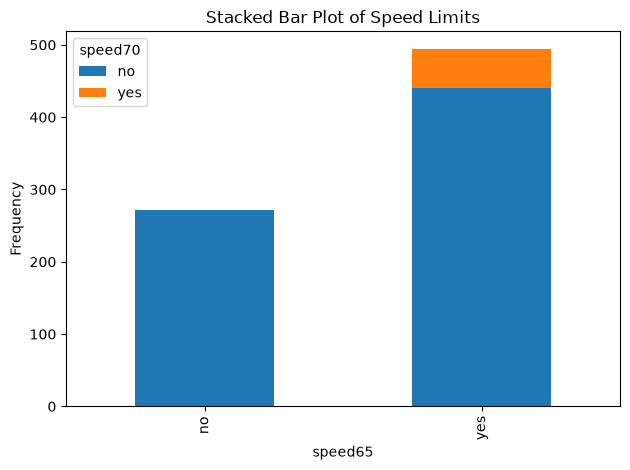

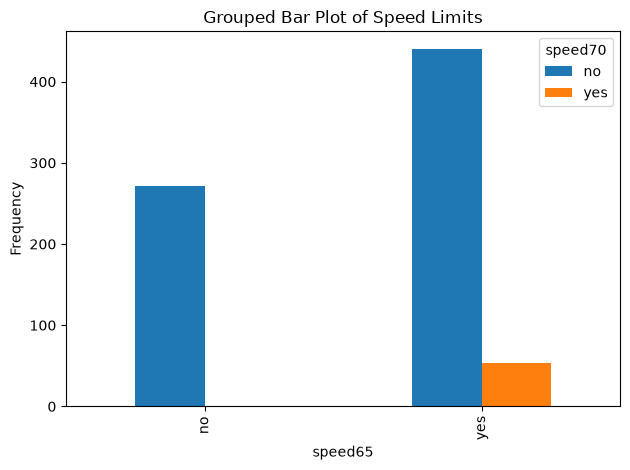

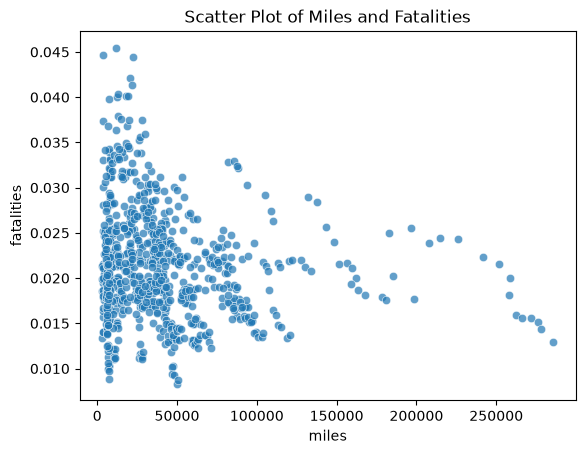

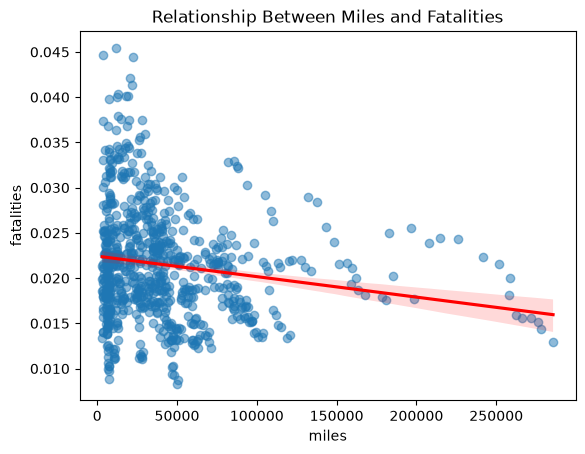

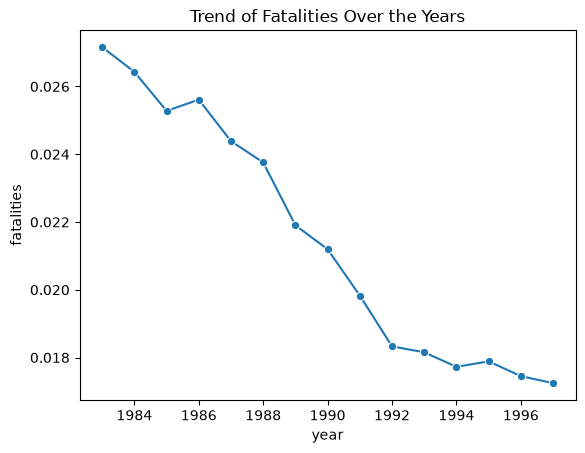


CORRELATION MATRIX
              year  miles  fatalities  income    age
year        1.000  0.123      -0.559   0.781  0.370
miles       0.123  1.000      -0.161   0.206  0.083
fatalities -0.559 -0.161       1.000  -0.704 -0.375
income      0.781  0.206      -0.704   1.000  0.408
age         0.370  0.083      -0.375   0.408  1.000


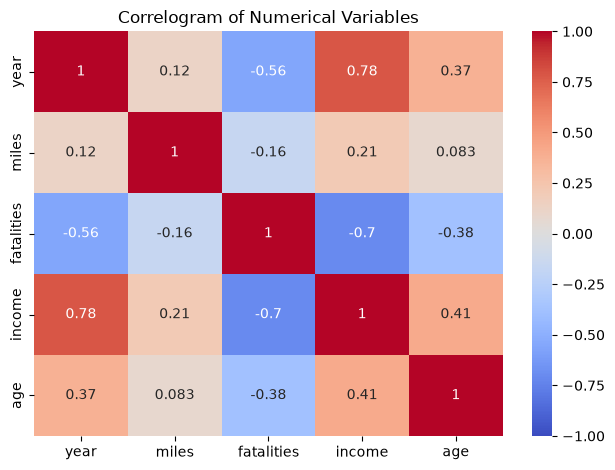


AVERAGE FATALITIES BY SPEED65
   speed65  average_fatalities
0      no            0.023836
1     yes            0.020202


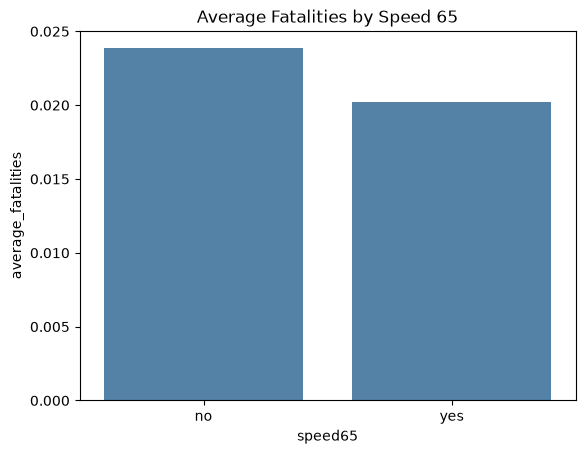

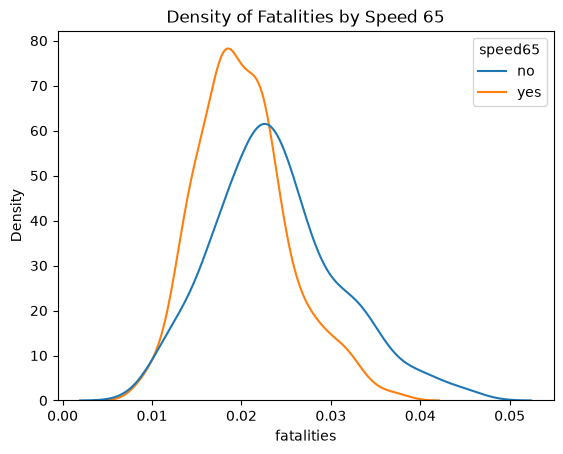

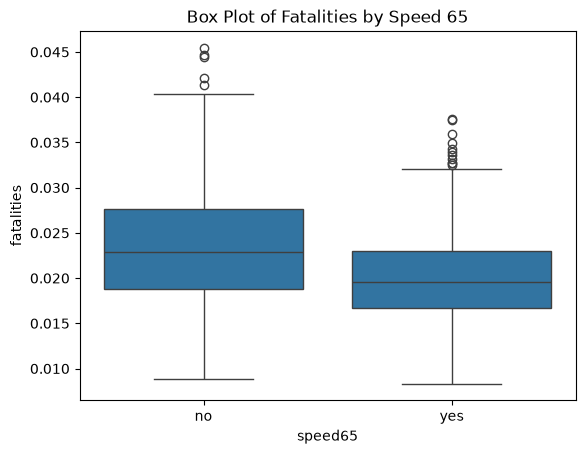

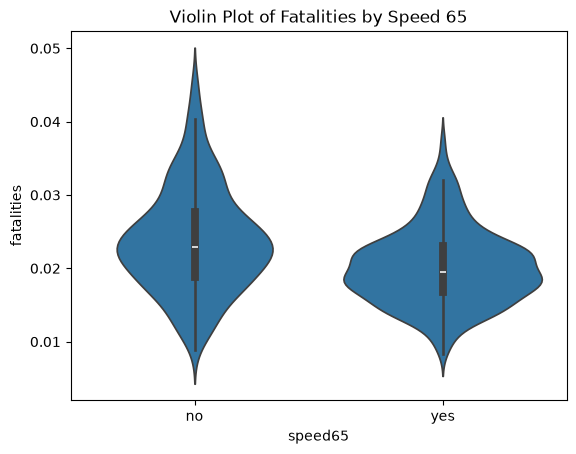

In [2]:
for c in ["speed65", "speed70", "state", "alcohol"]:
    if c in df: df[c] = df[c].astype("category")
if {"speed65","speed70"}.issubset(df.columns):
    table = pd.crosstab(df["speed65"], df["speed70"])
    print("\nCONTINGENCY TABLE\n", table)
    table.plot(kind="bar", stacked=True, title="Stacked Bar Plot of Speed Limits"); plt.ylabel("Frequency"); plt.tight_layout(); plt.show()
    table.plot(kind="bar", stacked=False, title="Grouped Bar Plot of Speed Limits"); plt.ylabel("Frequency"); plt.tight_layout(); plt.show()
if {"miles","fatalities"}.issubset(df.columns):
    sns.scatterplot(data=df, x="miles", y="fatalities", alpha=.7)
    plt.title("Scatter Plot of Miles and Fatalities"); plt.show()
    sns.regplot(data=df, x="miles", y="fatalities", scatter_kws={"alpha":.5}, line_kws={"color":"red"})
    plt.title("Relationship Between Miles and Fatalities"); plt.show()
if {"year","fatalities"}.issubset(df.columns):
    annual = df.groupby("year", as_index=False, observed=False)["fatalities"].mean()
    sns.lineplot(data=annual, x="year", y="fatalities", marker="o")
    plt.title("Trend of Fatalities Over the Years"); plt.show()
num_cols = [c for c in ["year","miles","fatalities","income","age"] if c in df and pd.api.types.is_numeric_dtype(df[c])]
if len(num_cols)>1:
    corr = df[num_cols].corr()
    print("\nCORRELATION MATRIX\n", corr.round(3))
    sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1); plt.title("Correlogram of Numerical Variables"); plt.tight_layout(); plt.show()
if {"speed65","fatalities"}.issubset(df.columns):
    bar_data = df.groupby("speed65", observed=False)["fatalities"].mean().reset_index(name="average_fatalities")
    print("\nAVERAGE FATALITIES BY SPEED65\n", bar_data)
    sns.barplot(data=bar_data, x="speed65", y="average_fatalities", color="steelblue"); plt.title("Average Fatalities by Speed 65"); plt.show()
    sns.kdeplot(data=df, x="fatalities", hue="speed65", fill=False, common_norm=False); plt.title("Density of Fatalities by Speed 65"); plt.show()
    sns.boxplot(data=df, x="speed65", y="fatalities"); plt.title("Box Plot of Fatalities by Speed 65"); plt.show()
    sns.violinplot(data=df, x="speed65", y="fatalities"); plt.title("Violin Plot of Fatalities by Speed 65"); plt.show()